## 01_data_exploration

## imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## loading

Load the raw sales data and store metadata

In [2]:
train = pd.read_csv('../data/train.csv', low_memory=False)
store = pd.read_csv('../data/store.csv', low_memory=False)

print(train.shape)
train.head()

(1017209, 9)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [3]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

In [4]:
print(store.shape)
store.head()

(1115, 10)


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [5]:
store.isnull().sum()

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

In [6]:
print(train['Date'].min(), train['Date'].max())

2013-01-01 2015-07-31


Summary:
- no missing values in train.csv
- spans 2013-01-01 to 2015-07-31
- covers 1,115 stores

## merging 
#### merge the train and store csvs with left join

In [7]:
df = train.merge(store, on='Store', how='left')

print(df.shape)
df.head()

(1017209, 18)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [8]:
df.isnull().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64

merging the csvs introduces missing values in competition/Promo2 columns. Need to check why

#### checking if the Promo2 dependencies are always missing if Store is not taking part in Promo2

In [9]:
df[df['Promo2'] == 0].isnull().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            1884
CompetitionOpenSinceMonth    138496
CompetitionOpenSinceYear     138496
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64

missing count for Promo2Since* columns exactly matches rows where Promo2==0. not actually missing, just "not applicable."

#### now checking competition signals

In [10]:
df[df['CompetitionDistance'].notnull()].isnull().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance               0
CompetitionOpenSinceMonth    320706
CompetitionOpenSinceYear     320706
Promo2                            0
Promo2SinceWeek              506147
Promo2SinceYear              506147
PromoInterval                506147
dtype: int64

Finding: missing count for CompetitionOpenSinceMonth/Year barely drops when filtering to known competitors, this rules out "no competitor." 

Means: competitor exists, open date just unrecorded. Leaving these unfilled for now, better as a derived "time since competitor opened" feature later.

## feature filling/engineering

Applying the decisions above: 
- fill CompetitionDistance with the median (unknown ≈ assume typical)
- fill Promo2Since* / PromoInterval with 0 / empty string (missing = not applicable, not unknown).

In [11]:
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(df['CompetitionDistance'].median())

df.isnull().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance               0
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64

In [12]:
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)

df['PromoInterval']   = df['PromoInterval'].fillna("")

df.isnull().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance               0
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek                   0
Promo2SinceYear                   0
PromoInterval                     0
dtype: int64

## plotting

Look at Store 1's sales over time to check for trend/seasonality by eye, before running any actual checks.

In [13]:
store = df[df['Store'] == 1]

store['Date'] = pd.to_datetime(store['Date']) #Date was stored as text, not a real date type

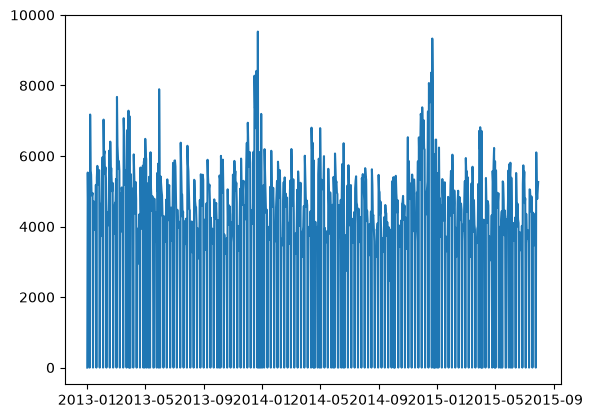

In [14]:
plot = plt.plot(store['Date'], store['Sales'])
plt.show()

Observations: sales drop to zero on a regular cycle, a repeating weekly zig-zag on open days, and two tall spikes around late 2013/2014. 

In [15]:
store[store['Open'] == 1].groupby('DayOfWeek')['Sales'].mean()

DayOfWeek
1    5177.968750
2    4685.626866
3    4555.712121
4    4457.838710
5    4726.480620
6    4942.970149
Name: Sales, dtype: float64

Finding: for Store 1, sales are highest early week (day 1), dip toward mid-week (day 4), confirms zig-zag pattern

In [16]:
store['StateHoliday'].unique()

<StringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str

In [17]:
store[store['Sales'] == store['Sales'].max()]

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
619155,1,1,2013-12-23,9528,1130,1,0,0,1,c,a,1270.0,9.0,2008.0,0,0.0,0.0,


Finding: peak sales day for Store 1 is Dec 23, 2013, StateHoliday==0 (normal day, not the holiday itself)

### check trends apply broadly

Store 1's patterns could be a fluke — repeat the same checks across all 1,115 stores.

##### check sales per day

In [18]:
df[df['Open'] == 1].groupby('DayOfWeek')['Sales'].mean()

DayOfWeek
1    8216.073074
2    7088.113656
3    6728.122978
4    6767.310159
5    7072.677012
6    5874.840238
7    8224.723908
Name: Sales, dtype: float64

Surprising result: Sunday shows the highest average sales, opposite of expectations (most stores closed Sundays). 

Before trusting it, check how many stores are actually open on Sundays.

##### investigate sunday discrepency

In [19]:
df[df['Open'] == 1].groupby('DayOfWeek')['Sales'].count()

DayOfWeek
1    137560
2    143961
3    141936
4    134644
5    138640
6    144058
7      3593
Name: Sales, dtype: int64

Finding: only 3,593 store-days open on Sundays vs 130,000+ other days — tiny sample skewing the average, not a real pattern.

##### check christmas spike

In [20]:
daily_sales = df.groupby('Date')['Sales'].sum()
daily_sales.sort_values(ascending=False).head(10)

Date
2013-12-16    15623548
2013-12-23    14350056
2014-06-30    13308602
2013-12-17    13053993
2013-12-02    12972440
2015-03-30    12371453
2013-12-20    12334496
2013-12-18    12189674
2014-12-15    12133381
2014-03-31    12062933
Name: Sales, dtype: int64

Finding: 6 of top 10 highest-selling days are in December (holiday effect confirmed broadly). Other 4 aren't December

##### investigate non-december spikes

In [21]:
print(df['Promo'].mean())

0.3815145166824124


Baseline: ~38% of stores run a promo on a typical day — comparison point for the spike dates.

In [22]:
print(df[df['Date'] == '2014-06-30']['Promo'].mean())
print(df[df['Date'] == '2015-03-30']['Promo'].mean())
print(df[df['Date'] == '2014-03-31']['Promo'].mean())

1.0
1.0
1.0


Finding: all three non-December top-10 sales days had 100% of stores running a promo vs 38% baseline — company-wide promo events, not payday. 

Verified across all three dates. Promo looks like one of the strongest predictors in this dataset.

Summary: 
- weekly seasonality (Monday high, Sunday mostly-closed with a skewed minority open)
- holiday effect (pre-Christmas spike)
- promo effect (biggest non-holiday spikes = 100% promo days)